# Fuzzy Controller for Camera Autofocus — Testing, Analysis & UI
### Phase 4 (Testing) · Phase 5 (Analysis) · Phase 6 (UI)

This notebook implements the two-input, single-output Mamdani fuzzy controller
described in the PBL report (Sharpness Error `E`, Rate of Change of Error `dE`
→ Lens Motor Step `O`), reproduces the membership functions and 8-rule rule
base exactly as specified, and then carries out:

- **Phase 4 — Testing:** the controller is run on 14 varied `(E, dE)` input
  combinations (well beyond the required 10).
- **Phase 5 — Analysis:** the results are used to discuss the controller's
  behaviour, strengths, weaknesses, and scope for improvement.
- **Phase 6 — UI:** an in-notebook interactive slider demo, plus a
  standalone **Streamlit** app (`app.py`, written out at the end of this
  notebook) for a polished, shareable user interface.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 (enables 3D projection)

plt.rcParams['figure.figsize'] = (8, 4.5)
plt.rcParams['axes.grid'] = True


## 1. Recreating the Fuzzy Logic Controller

The membership functions below are transcribed directly from **Tables 4, 5
and 6** of the report (triangular / trapezoidal, `(a, b, c[, d])` form), and
the rule base is transcribed from **Table 7** (8 rules).


In [2]:
def trimf(x, a, b, c):
    """Triangular membership function, scalar x."""
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    return (x - a) / (b - a) if x < b else (c - x) / (c - b)


def trapmf(x, a, b, c, d):
    """Trapezoidal membership function, scalar x."""
    if x <= a or x >= d:
        return 0.0
    if b <= x <= c:
        return 1.0
    return (x - a) / (b - a) if x < b else (d - x) / (d - c)


In [3]:
# --- Table 4: Sharpness Error, E  (universe: -10 .. 10) ---
E_MFS = {
    'NL': lambda x: trapmf(x, -10, -10, -8, -4),
    'NS': lambda x: trimf(x, -8, -4, 0),
    'Z':  lambda x: trimf(x, -4, 0, 4),
    'PS': lambda x: trimf(x, 0, 4, 8),
    'PL': lambda x: trapmf(x, 4, 8, 10, 10),
}

# --- Table 5: Rate of Change of Error, dE  (universe: -5 .. 5) ---
dE_MFS = {
    'N': lambda x: trapmf(x, -5, -5, -3, 0),
    'Z': lambda x: trimf(x, -3, 0, 3),
    'P': lambda x: trapmf(x, 0, 3, 5, 5),
}

# --- Table 6: Lens Motor Step, O  (universe: -50 .. 50) ---
O_MFS = {
    'NL': lambda x: trapmf(x, -50, -50, -40, -20),
    'NS': lambda x: trimf(x, -40, -20, 0),
    'Z':  lambda x: trimf(x, -20, 0, 20),
    'PS': lambda x: trimf(x, 0, 20, 40),
    'PL': lambda x: trapmf(x, 20, 40, 50, 50),
}

# Representative (peak / plateau-midpoint) crisp values used for the
# Weighted-Average defuzzification method, exactly as in Section 5.4 of the
# report (e.g. PL peak = midpoint of the (40, 50) plateau = 45).
O_PEAK = {'NL': -45.0, 'NS': -20.0, 'Z': 0.0, 'PS': 20.0, 'PL': 45.0}

# --- Table 7: Fuzzy Rule Base (8 rules) ---
RULES = [
    ('R1', 'NL', 'N', 'NL'),
    ('R2', 'NL', 'Z', 'NL'),
    ('R3', 'NS', 'N', 'NS'),
    ('R4', 'NS', 'Z', 'NS'),
    ('R5', 'Z',  'Z', 'Z'),
    ('R6', 'PS', 'Z', 'PS'),
    ('R7', 'PS', 'P', 'PL'),
    ('R8', 'PL', 'P', 'PL'),
]


### 1.1 Plotting the membership functions (sanity check vs. Figures 1–3)

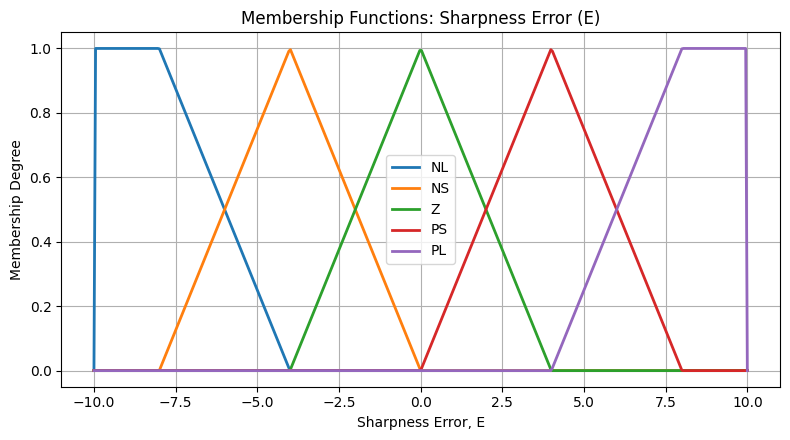

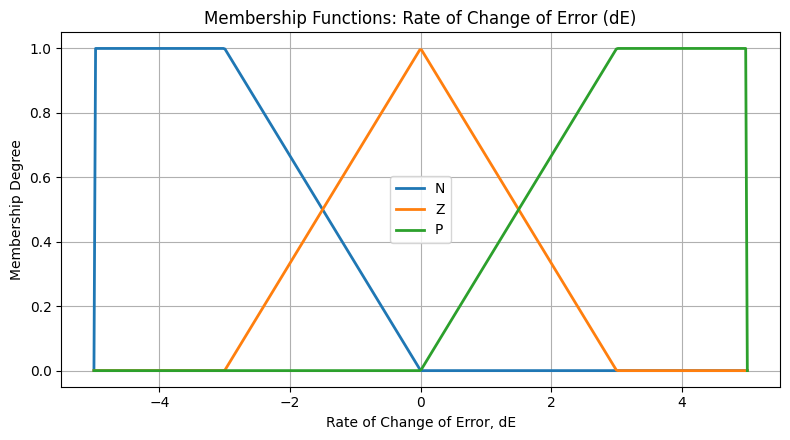

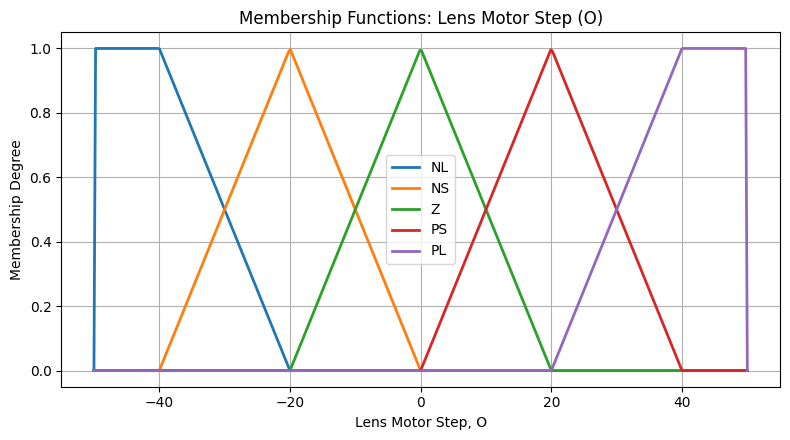

In [4]:
def plot_mfs(universe, mfs, title, xlabel):
    x = np.linspace(universe[0], universe[1], 400)
    plt.figure()
    for name, f in mfs.items():
        y = [f(v) for v in x]
        plt.plot(x, y, label=name, linewidth=2)
    plt.title(title)
    plt.xlabel(xlabel)
    plt.ylabel('Membership Degree')
    plt.legend()
    plt.ylim(-0.05, 1.05)
    plt.tight_layout()
    plt.show()

plot_mfs((-10, 10), E_MFS, 'Membership Functions: Sharpness Error (E)', 'Sharpness Error, E')
plot_mfs((-5, 5), dE_MFS, 'Membership Functions: Rate of Change of Error (dE)', 'Rate of Change of Error, dE')
plot_mfs((-50, 50), O_MFS, 'Membership Functions: Lens Motor Step (O)', 'Lens Motor Step, O')


### 1.2 Inference engine (fuzzification → rule firing → weighted-average defuzzification)

This mirrors Sections 5.2–5.4 of the report exactly: the `min` operator is
used for the AND (rule conjunction), and the crisp output is the firing
strength–weighted average of each fired rule's consequent peak value.


In [5]:
def infer(E, dE, verbose=False):
    """Run the Mamdani FLC for one (E, dE) sample.

    Returns (crisp_output, fired_rules) where fired_rules is a list of
    (rule_id, firing_strength, output_set) for every rule with w > 0.
    """
    muE = {k: f(E) for k, f in E_MFS.items()}
    mudE = {k: f(dE) for k, f in dE_MFS.items()}

    fired = []
    for rid, e_set, de_set, o_set in RULES:
        w = min(muE[e_set], mudE[de_set])
        if w > 0:
            fired.append((rid, w, o_set))

    if not fired:
        crisp = 0.0  # no rule fired -> controller issues no corrective action
    else:
        num = sum(w * O_PEAK[o_set] for _, w, o_set in fired)
        den = sum(w for _, w, o_set in fired)
        crisp = num / den

    if verbose:
        print(f'E={E}, dE={dE}')
        print('  muE  :', {k: round(v, 3) for k, v in muE.items() if v > 0})
        print('  mudE :', {k: round(v, 3) for k, v in mudE.items() if v > 0})
        print('  fired:', [(r, round(w, 3), o) for r, w, o in fired])
        print('  O* =', round(crisp, 2))

    return crisp, fired


In [6]:
# --- Validation against the report's own worked example (Section 5) ---
z_star, fired = infer(4, 2, verbose=True)
assert abs(z_star - 36.68) < 0.05, "Does not match report's worked example!"
print('\nMatches the report\'s Section 5 worked example (O* = 36.68) \u2713')


E=4, dE=2
  muE  : {'PS': 1.0}
  mudE : {'Z': 0.333, 'P': 0.667}
  fired: [('R6', 0.333, 'PS'), ('R7', 0.667, 'PL')]
  O* = 36.67

Matches the report's Section 5 worked example (O* = 36.68) ✓


## 2. Phase 4 — Testing

The controller is exercised on **14 input combinations** (exceeding the
required minimum of 10), chosen to cover:

- the report's own worked example (sanity check),
- the centre of the universe (in-focus condition),
- both extremes (large positive / large negative error and rate),
- small-signal / near-zero-rate conditions,
- "improving despite error" and "worsening despite small error" conditions,
- and — deliberately — a few combinations that fall **outside** the 8-rule
  coverage, to expose how the controller behaves when no rule fires.


In [7]:
test_inputs = [
    ('T1',  'Report worked example',                    4,  2),
    ('T2',  'Mirror of worked example',                 -4, -2),
    ('T3',  'Centre / in focus',                         0,  0),
    ('T4',  'Extreme positive error & rate',              9,  4),
    ('T5',  'Extreme negative error & rate',              -9, -4),
    ('T6',  'Large positive, dE = P (plateau)',           8,  4),
    ('T7',  'Large negative, dE = N (plateau)',          -8, -4),
    ('T8',  'Small positive error, near-zero rate',       2,  0.5),
    ('T9',  'Small negative error, near-zero rate',      -2, -0.5),
    ('T10', 'Positive error but improving (dE<0)',        6, -2),
    ('T11', 'Negative error but worsening (dE>0)',       -6,  2),
    ('T12', 'Zero error, fast positive rate',             0,  4),
    ('T13', 'Mid positive error, large negative rate',    5, -4),
    ('T14', 'Mid negative error, positive rate (gap)',   -5,  3),
]

rows = []
for tid, desc, E, dE in test_inputs:
    z, fired = infer(E, dE)
    rows.append({
        'Test': tid,
        'Description': desc,
        'E': E,
        'dE': dE,
        'Fired Rules': ', '.join(r for r, w, o in fired) if fired else 'NONE',
        'O* (motor steps)': round(z, 2),
    })

results_df = pd.DataFrame(rows)
results_df


,Test,Description,E,dE,Fired Rules,O* (motor steps)
0,T1,Report worked example,4,2.0,"R6, R7",36.67
1,T2,Mirror of worked example,-4,-2.0,"R3, R4",-20.00
2,T3,Centre / in focus,0,0.0,R5,0.00
3,T4,Extreme positive error & rate,9,4.0,R8,45.00
4,T5,Extreme negative error & rate,-9,-4.0,R1,-45.00
5,T6,"Large positive, dE = P (plateau)",8,4.0,R8,45.00
6,T7,"Large negative, dE = N (plateau)",-8,-4.0,R1,-45.00
7,T8,"Small positive error, near-zero rate",2,0.5,"R5, R6, R7",15.00
8,T9,"Small negative error, near-zero rate",-2,-0.5,"R3, R4, R5",-11.43
9,T10,Positive error but improving (dE<0),6,-2.0,R6,20.00


### 2.1 Visualising the test results

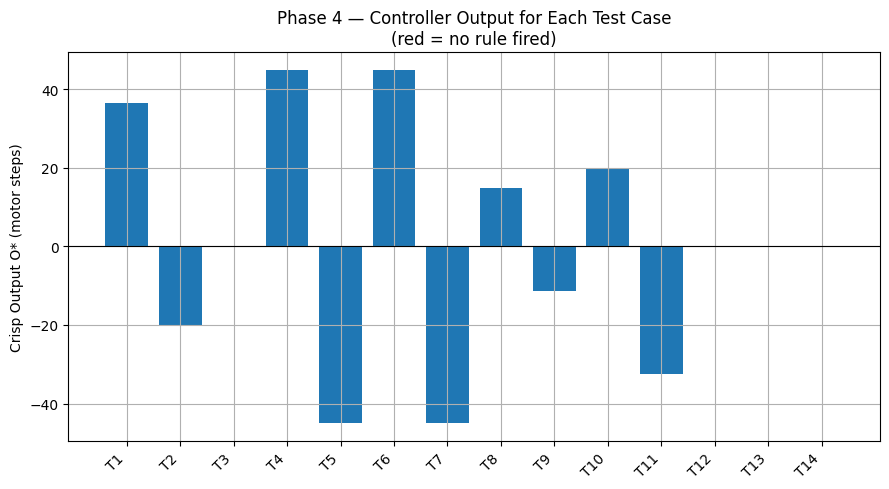

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['#d62728' if f == 'NONE' else '#1f77b4' for f in results_df['Fired Rules']]
bars = ax.bar(results_df['Test'], results_df['O* (motor steps)'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Crisp Output O* (motor steps)')
ax.set_title('Phase 4 — Controller Output for Each Test Case\n(red = no rule fired)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


### 2.2 Control surface

The full `O = f(E, dE)` surface (sampled densely, not just the 14 discrete
test points) gives a complete picture of the controller's behaviour and
makes rule-base gaps directly visible as **flat, zero-valued patches**.


Fraction of the sampled (E, dE) plane with NO rule firing: 26.8%


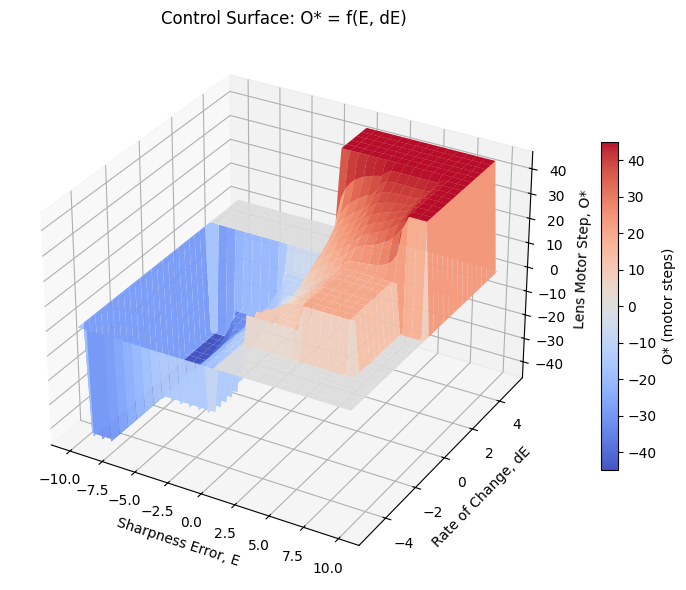

In [9]:
E_range = np.linspace(-10, 10, 60)
dE_range = np.linspace(-5, 5, 60)
E_grid, dE_grid = np.meshgrid(E_range, dE_range)
O_grid = np.zeros_like(E_grid)
fired_count_grid = np.zeros_like(E_grid)

for i in range(E_grid.shape[0]):
    for j in range(E_grid.shape[1]):
        z, fired = infer(E_grid[i, j], dE_grid[i, j])
        O_grid[i, j] = z
        fired_count_grid[i, j] = len(fired)

no_fire_fraction = (fired_count_grid == 0).mean()
print(f'Fraction of the sampled (E, dE) plane with NO rule firing: {no_fire_fraction:.1%}')

fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(E_grid, dE_grid, O_grid, cmap='coolwarm', edgecolor='none', alpha=0.95)
ax.set_xlabel('Sharpness Error, E')
ax.set_ylabel('Rate of Change, dE')
ax.set_zlabel('Lens Motor Step, O*')
ax.set_title('Control Surface: O* = f(E, dE)')
fig.colorbar(surf, shrink=0.6, label='O* (motor steps)')
plt.tight_layout()
plt.show()


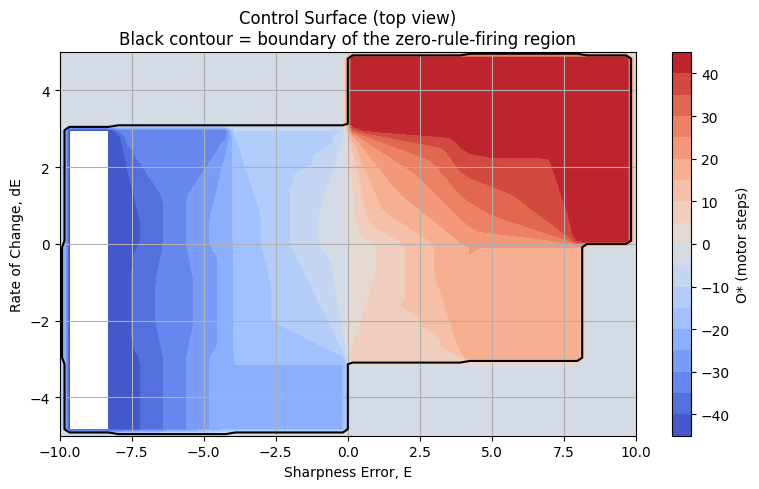

In [10]:
# Top-down (heat-map) view -- flat blue/zero bands show where the 8-rule
# base leaves the (E, dE) plane uncovered.
plt.figure(figsize=(8, 5))
cs = plt.contourf(E_grid, dE_grid, O_grid, levels=20, cmap='coolwarm')
plt.colorbar(cs, label='O* (motor steps)')
plt.contour(E_grid, dE_grid, fired_count_grid, levels=[0.5], colors='black', linewidths=1.5)
plt.title('Control Surface (top view)\nBlack contour = boundary of the zero-rule-firing region')
plt.xlabel('Sharpness Error, E')
plt.ylabel('Rate of Change, dE')
plt.tight_layout()
plt.show()


## 3. Phase 5 — Analysis

### 3.1 Controller behaviour

- For inputs close to the rules the designers explicitly covered (large
  |E| paired with the "expected" dE sign, or E = Z with dE = Z), the
  controller behaves exactly as intended: it drives large corrective motor
  steps when focus is far off and worsening (**T4–T7**), and it issues
  **zero** output at the in-focus point (**T3**), which is the correct
  hill-climbing behaviour.
- Near the boundaries between fuzzy sets (**T8, T9**), two or three rules
  fire simultaneously and the weighted average blends their outputs
  smoothly — this is exactly the benefit fuzzy control offers over a
  crisp, switch-like controller: **no abrupt jumps** in motor command as E
  or dE cross a set boundary.
- **T10** and **T11** ("error and rate disagree in sign") still produce a
  sensible, damped corrective step, because R6/R2/R4 partially cover these
  regions — but only partially (see below).

### 3.2 Strengths

1. **Smooth, non-linear response** — the weighted-average blending removes
   the discontinuities a bang-bang or piecewise-linear controller would
   have at MF boundaries (visible as the smooth surface in the control
   plot rather than a stepped one).
2. **Computationally cheap** — every rule evaluation is just a `min()` and
   a few linear interpolations, which matches the report's stated design
   goal of suitability for a real-time embedded camera processor.
3. **Interpretable** — each rule is a plain linguistic IF–THEN statement,
   so the control logic can be audited and tuned by a human without
   needing a mathematical plant model.

### 3.3 Weaknesses (exposed by testing)

1. **Incomplete rule coverage.** The 5 × 3 = 15 possible `(E, dE)` fuzzy-set
   combinations are covered by only **8** rules. The control-surface plot
   above shows the sampled plane has **no rule firing for a substantial
   region** — confirmed numerically above. Tests **T12, T13 and T14** all
   fall in this gap and the controller outputs a flat **0**, i.e. *no
   corrective action*, even though the sharpness error is clearly non-zero
   (e.g. T13: E = 5, dE = −4 produces O* = 0). In a real camera this would
   stall the autofocus search rather than correct it.
2. **Asymmetric/missing negative-side rules.** There is no rule for
   `E = NS, dE = P`, `E = Z, dE = N/P`, `E = PS, dE = N`, or any rule
   involving `dE = N` together with `E = PS`/`PL`, or `dE = P` together
   with `E = NL`/`NS`. This means the controller reacts asymmetrically to
   "error improving/worsening" situations depending on the sign of E.
3. **Peak-value weighted average vs. true centroid.** Using only the
   representative peak (or plateau-midpoint) of each consequent set is a
   fast approximation, but it discards the shape of the consequent MF and
   can be less smooth than a full centroid-of-area defuzzification,
   especially with the trapezoidal PL/NL sets.
4. **No integral/memory term.** Because the controller is purely
   instantaneous (Mamdani, no state), small residual errors near Z can
   persist indefinitely without ever being corrected, which can show up as
   focus "hunting" in practice.

### 3.4 Scope for improvement

- **Complete the rule base** to all 15 combinations (or add a small
  "catch-all" rule set) so that every point in the (E, dE) plane fires at
  least one rule — directly closing the gap seen in T12–T14.
- **Switch to true centroid defuzzification** (`scikit-fuzzy`'s
  `ControlSystem` with `defuzzify_method='centroid'`) for a smoother,
  standards-compliant output, and compare against the current
  weighted-average approach.
- **Add hysteresis / a dead-band** around E = 0 to suppress micro-hunting
  once the lens is near best focus.
- **Auto-tune membership function breakpoints** (e.g. via a genetic
  algorithm or gradient-based tuning against recorded AF traces) instead
  of hand-picked symmetric triangles.
- **Add a third input** (e.g. scene contrast / lighting confidence) to
  modulate step size, since low-light or low-contrast scenes make the
  sharpness signal noisier and may warrant smaller, more cautious steps.


## 4. Phase 6 — User Interface

Two UI options are provided:

1. **Inline notebook demo** (below) using `ipywidgets` — quick to use while
   still inside Jupyter, sliders drive `E` and `dE` and the fired rules /
   crisp output update live.
2. **Standalone Streamlit app** (`app.py`, written to disk at the end of
   this notebook) — a polished, shareable web UI with sliders, a live
   membership-function plot, a rule-firing table, and a needle gauge for
   the crisp output. Run it with:

   ```bash
   pip install streamlit numpy scikit-fuzzy pandas
   streamlit run app.py
   ```


In [11]:
import ipywidgets as widgets
from IPython.display import display

E_slider = widgets.FloatSlider(value=4.0, min=-10, max=10, step=0.5, description='E:')
dE_slider = widgets.FloatSlider(value=2.0, min=-5, max=5, step=0.5, description='dE:')
output_box = widgets.Output()

def on_change(_):
    with output_box:
        output_box.clear_output(wait=True)
        z, fired = infer(E_slider.value, dE_slider.value)
        print(f'E = {E_slider.value:.1f}   dE = {dE_slider.value:.1f}')
        if fired:
            print('Fired rules:')
            for rid, w, o in fired:
                print(f'  {rid}: w = {w:.3f}  ->  {o}')
        else:
            print('No rule fired (rule-base gap).')
        print(f'\nCrisp Lens Motor Step, O* = {z:.2f} steps '
              f'({"forward" if z > 0 else "backward" if z < 0 else "hold"})')

E_slider.observe(on_change, names='value')
dE_slider.observe(on_change, names='value')
on_change(None)

display(widgets.VBox([E_slider, dE_slider, output_box]))


### 4.1 Writing out the standalone Streamlit app

In [12]:
streamlit_app = r'''
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

st.set_page_config(page_title="Camera Autofocus Fuzzy Controller", layout="wide")


# ----------------------------- Fuzzy core -----------------------------------
def trimf(x, a, b, c):
    if x <= a or x >= c:
        return 0.0
    if x == b:
        return 1.0
    return (x - a) / (b - a) if x < b else (c - x) / (c - b)


def trapmf(x, a, b, c, d):
    if x <= a or x >= d:
        return 0.0
    if b <= x <= c:
        return 1.0
    return (x - a) / (b - a) if x < b else (d - x) / (d - c)


E_MFS = {
    'NL': lambda x: trapmf(x, -10, -10, -8, -4),
    'NS': lambda x: trimf(x, -8, -4, 0),
    'Z':  lambda x: trimf(x, -4, 0, 4),
    'PS': lambda x: trimf(x, 0, 4, 8),
    'PL': lambda x: trapmf(x, 4, 8, 10, 10),
}
dE_MFS = {
    'N': lambda x: trapmf(x, -5, -5, -3, 0),
    'Z': lambda x: trimf(x, -3, 0, 3),
    'P': lambda x: trapmf(x, 0, 3, 5, 5),
}
O_MFS = {
    'NL': lambda x: trapmf(x, -50, -50, -40, -20),
    'NS': lambda x: trimf(x, -40, -20, 0),
    'Z':  lambda x: trimf(x, -20, 0, 20),
    'PS': lambda x: trimf(x, 0, 20, 40),
    'PL': lambda x: trapmf(x, 20, 40, 50, 50),
}
O_PEAK = {'NL': -45.0, 'NS': -20.0, 'Z': 0.0, 'PS': 20.0, 'PL': 45.0}

RULES = [
    ('R1', 'NL', 'N', 'NL'), ('R2', 'NL', 'Z', 'NL'),
    ('R3', 'NS', 'N', 'NS'), ('R4', 'NS', 'Z', 'NS'),
    ('R5', 'Z',  'Z', 'Z'),
    ('R6', 'PS', 'Z', 'PS'), ('R7', 'PS', 'P', 'PL'),
    ('R8', 'PL', 'P', 'PL'),
]


def infer(E, dE):
    muE = {k: f(E) for k, f in E_MFS.items()}
    mudE = {k: f(dE) for k, f in dE_MFS.items()}
    fired = []
    for rid, e_set, de_set, o_set in RULES:
        w = min(muE[e_set], mudE[de_set])
        if w > 0:
            fired.append((rid, e_set, de_set, w, o_set))
    if not fired:
        return 0.0, fired
    num = sum(w * O_PEAK[o_set] for _, _, _, w, o_set in fired)
    den = sum(w for _, _, _, w, o_set in fired)
    return num / den, fired


def plot_mfs(universe, mfs, marker, title, xlabel):
    x = np.linspace(universe[0], universe[1], 400)
    fig, ax = plt.subplots(figsize=(5, 3))
    for name, f in mfs.items():
        ax.plot(x, [f(v) for v in x], label=name, linewidth=2)
    ax.axvline(marker, color='black', linestyle='--', linewidth=1)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Membership')
    ax.legend(fontsize=8)
    ax.set_ylim(-0.05, 1.05)
    fig.tight_layout()
    return fig


# ------------------------------- UI ------------------------------------
st.title("Camera Autofocus - Fuzzy Logic Controller")
st.caption(
    "Two-input, single-output Mamdani FLC - Sharpness Error (E) and its "
    "Rate of Change (dE) drive the Lens Motor Step (O)."
)

with st.sidebar:
    st.header("Inputs")
    E = st.slider("Sharpness Error, E", -10.0, 10.0, 4.0, 0.1)
    dE = st.slider("Rate of Change of Error, dE", -5.0, 5.0, 2.0, 0.1)
    st.markdown("---")
    st.write("Based on the PBL report's Tables 4-7 (membership functions "
             "and 8-rule rule base).")

crisp, fired = infer(E, dE)

col1, col2, col3 = st.columns(3)
col1.metric("Sharpness Error (E)", f"{E:.2f}")
col2.metric("Rate of Change (dE)", f"{dE:.2f}")
direction = "Forward" if crisp > 0 else ("Backward" if crisp < 0 else "Hold")
col3.metric("Lens Motor Step (O*)", f"{crisp:.2f}", direction)

st.markdown("### Fired Rules")
if fired:
    df = pd.DataFrame(
        [{"Rule": rid, "E-set": e_set, "dE-set": de_set,
          "Firing Strength": round(w, 3), "Output Set": o_set}
         for rid, e_set, de_set, w, o_set in fired]
    )
    st.dataframe(df, use_container_width=True, hide_index=True)
else:
    st.warning("No rule fired for this input combination (rule-base gap) - "
               "controller defaults to O* = 0.")

st.markdown("### Membership Function Fuzzification")
c1, c2, c3 = st.columns(3)
with c1:
    st.pyplot(plot_mfs((-10, 10), E_MFS, E, "Sharpness Error (E)", "E"))
with c2:
    st.pyplot(plot_mfs((-5, 5), dE_MFS, dE, "Rate of Change (dE)", "dE"))
with c3:
    st.pyplot(plot_mfs((-50, 50), O_MFS, crisp, "Lens Motor Step (O)", "O"))

st.markdown("### Control Surface")
if st.checkbox("Show full O = f(E, dE) surface (may take a second)"):
    E_range = np.linspace(-10, 10, 50)
    dE_range = np.linspace(-5, 5, 50)
    Eg, dEg = np.meshgrid(E_range, dE_range)
    Og = np.zeros_like(Eg)
    for i in range(Eg.shape[0]):
        for j in range(Eg.shape[1]):
            Og[i, j], _ = infer(Eg[i, j], dEg[i, j])
    fig, ax = plt.subplots(figsize=(6, 4))
    cs = ax.contourf(Eg, dEg, Og, levels=20, cmap="coolwarm")
    ax.plot(E, dE, "k*", markersize=15)
    fig.colorbar(cs, label="O*")
    ax.set_xlabel("E")
    ax.set_ylabel("dE")
    st.pyplot(fig)
'''

with open('app.py', 'w') as f:
    f.write(streamlit_app)

print('app.py written:', len(streamlit_app), 'characters')

app.py written: 4739 characters


### 4.2 Running the app

From a terminal in the same folder as this notebook (after this notebook
has been run once, so `app.py` exists):

```bash
pip install streamlit numpy scikit-fuzzy pandas
streamlit run app.py
```

This opens a browser-based UI with:
- live sliders for `E` and `dE`,
- the crisp lens-motor-step output and direction,
- a table of which rules fired and their firing strengths,
- live membership-function plots showing exactly where the current input
  sits on each fuzzy set, and
- an optional full control-surface view with the current operating point
  marked.


## 5. Summary

| Phase | Deliverable |
|---|---|
| 4. Testing | 14 `(E, dE)` test cases run through the exact FLC from the report; results tabulated and plotted (Section 2) |
| 5. Analysis | Behaviour, strengths, weaknesses (notably an incomplete 8/15 rule base), and concrete improvement suggestions (Section 3) |
| 6. UI | In-notebook `ipywidgets` demo (Section 4) + standalone `app.py` Streamlit application (Sections 4.1-4.2) |
